# 04 · ML1: aktif öğrenme ile QM/MM düzeltmesi
*Makale: Bölüm 2.2; Şekil 2 "Train ML1", Şekil 6–7.*

Pahalı DFT hesabını her yapı için yapmak yerine, $\Delta U_\text{etk}(x)$'i tahmin eden bir ML modeli eğitiyoruz:
- **Tanımlayıcılar:** her misafir atomunda çevrenin oluşturduğu elektrostatik potansiyel ve elektrik
  alanın karesi. Polarizasyon enerjisi yaklaşık $-\tfrac12\alpha|E|^2$ olduğu için bunlar fiziksel olarak anlamlı.
- **Model:** Gauss süreci (GP). Tahminle birlikte bir **belirsizlik** de veriyor.
- **Aktif öğrenme:** Her turda modelin *en emin olmadığı* yapıları DFT ile hesaplayıp eğitim kümesine
  ekliyoruz. Makale de aynı stratejiyi kullanıyor: "snapshots with high energy uncertainty".

Sonra ML1'i havuzdaki **tüm** yapılara uygulayıp serbest enerji düzeltmesini hesaplıyoruz:

$$\Delta G_\text{bağ}^\text{MM+ML1} = \Delta G_\text{bağ}^\text{MM} + \Delta A_\text{kompleks}^{\text{MM}\to\text{QM}} - \Delta A_\text{çözücü}^{\text{MM}\to\text{QM}}$$

(Burada $\Delta U = \Delta U_\text{etk}$; iç kısmın sadeleştiğini 03'te kontrol etmiştik.)

> **Basitleştirme:** Makale, kuvvet de veren bir ML potansiyeliyle MD yapıyor ve 10 ps'lik NEQ anahtarlama
> kullanıyor. Biz tek adımlı pertürbasyon (Zwanzig) kullanıyoruz. Bu, NEQ'nun "anlık anahtarlama" limiti.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))
from qfe import config, store
from qfe.plotting import C, LEG, LEG_TR
import numpy as np, matplotlib.pyplot as plt
# Ön ayar: "test" (hızlı kontrol), "demo" (ekibe gösterim), "standart" (daha güvenilir)
config.set_preset(os.environ.get("QFE_PRESET", "demo"))
print("Aktif ön ayar:", config.preset_name())

Aktif ön ayar: test


In [2]:
from qfe import qmmm, ml
from pyscf import lib
lib.num_threads(os.cpu_count())
pools = {leg: (lambda d: (d["X"], d["B"]))(store.load_npz(f"pool_{leg}.npz")) for leg in ["complex", "solvent"]}
regions = {leg: qmmm.QMRegion(leg) for leg in pools}
lab = qmmm.Labeler(regions, pools)
lab.load_dict(store.load_json("labels.json", default={}))
print("Önbellekteki DFT etiketi:", len(lab.cache_dft))
with store.timed("04_tanimlayicilar"):
    feats = {leg: ml.descriptors(regions[leg], *pools[leg]) for leg in pools}
print({leg: f.shape for leg, f in feats.items()})

Önbellekteki DFT etiketi: 8


[süre] 04_tanimlayicilar: 3.9 s
{'complex': (120, 32), 'solvent': (120, 32)}


In [3]:
p = config.P()
with store.timed("04_aktif_ogrenme") as rec:
    model1, train, val, hist = ml.active_learning(
        lab, feats, n_init=p["al_initial"], batch=p["al_batch"], rounds=p["al_rounds"], n_val=p["al_validation"])
    rec["n_dft"] = len(lab.cache_dft)
store.save_json("labels.json", lab.to_dict())
store.save_json("ml1.json", {"train": train, "val": val, "history": hist})

  tur 0: eğitim=  8  doğrulama RMSE=  2.95 kJ/mol (hedefin std'si 3.17)


  tur 1: eğitim= 12  doğrulama RMSE=  3.09 kJ/mol (hedefin std'si 3.05)


  tur 2: eğitim= 16  doğrulama RMSE=  2.70 kJ/mol (hedefin std'si 3.24)


  tur 3: eğitim= 20  doğrulama RMSE=  2.56 kJ/mol (hedefin std'si 3.69)
[süre] 04_aktif_ogrenme: 766.8 s


PosixPath('/home/claude/qb/results/test/ml1.json')

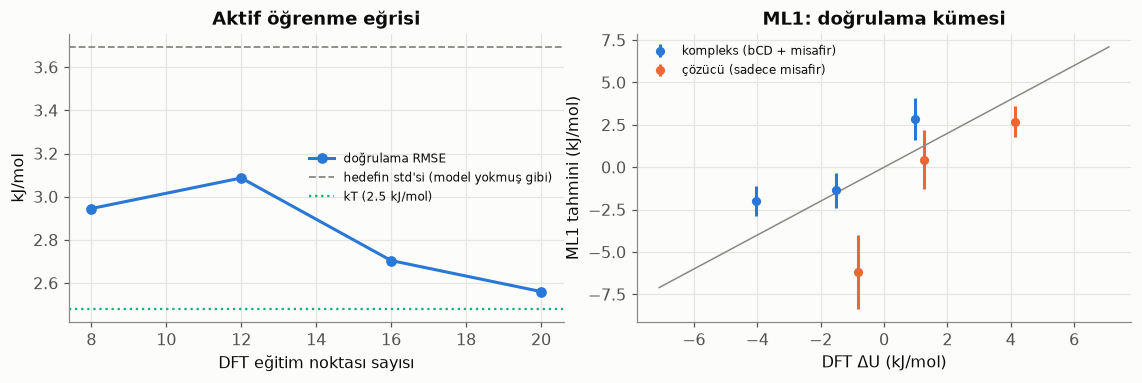

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.6))
axs[0].plot([h["n_train"] for h in hist], [h["rmse_val"] for h in hist], marker="o", color=C["blue"], label="doğrulama RMSE")
axs[0].axhline(hist[-1]["std_target"], color=C["muted"], ls="--", lw=1.2, label="hedefin std'si (model yokmuş gibi)")
axs[0].axhline(config.KT, color=C["aqua"], ls=":", lw=1.5, label="kT (2.5 kJ/mol)")
axs[0].set_xlabel("DFT eğitim noktası sayısı"); axs[0].set_ylabel("kJ/mol"); axs[0].set_title("Aktif öğrenme eğrisi")
axs[0].legend(fontsize=8)
Fv = np.array([feats[l][i] for l, i in val]); yv = np.array([lab.dU_dft(l, i) for l, i in val])
pv, sv = model1.predict(Fv, return_std=True)
for leg in ["complex", "solvent"]:
    m = np.array([l == leg for l, _ in val])
    axs[1].errorbar(yv[m] - yv.mean(), pv[m] - yv.mean(), yerr=sv[m], fmt="o", color=LEG[leg], ms=5, label=LEG_TR[leg])
lim = np.abs(np.concatenate([yv, pv]) - yv.mean()).max() * 1.15
axs[1].plot([-lim, lim], [-lim, lim], color=C["muted"], lw=1)
axs[1].set_xlabel("DFT ΔU (kJ/mol)"); axs[1].set_ylabel("ML1 tahmini (kJ/mol)"); axs[1].set_title("ML1: doğrulama kümesi")
axs[1].legend(fontsize=8); plt.tight_layout(); plt.show()

### ML1 ile tüm havuzda serbest enerji düzeltmesi

σ(ΔU) kompleks = 3.27 kJ/mol (1.3 kT), çözücü = 3.80 kJ/mol
ΔΔG düzeltme [üstel ortalama (Zwanzig)] =  -3.31 ± 0.98 kJ/mol  →  ΔG(MM+ML1) = -35.26 kJ/mol
ΔΔG düzeltme [2. mertebe kümülant     ] =  -1.87 ± 0.69 kJ/mol  →  ΔG(MM+ML1) = -33.82 kJ/mol


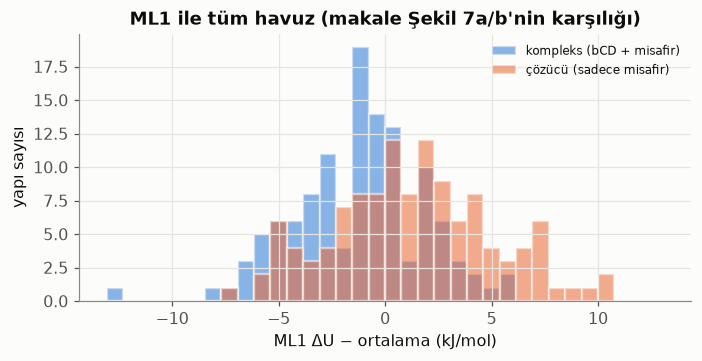

In [5]:
dU_ml1 = {leg: model1.predict(feats[leg]) for leg in pools}
corr1 = ml.binding_correction(dU_ml1["complex"], dU_ml1["solvent"])
r = store.load_json("results.json")
dG_mm, err_mm = r["dG_MM"]["dG_bind"], r["dG_MM"]["dG_bind_err"]
print(f"σ(ΔU) kompleks = {corr1['complex']['sigma']:.2f} kJ/mol ({corr1['complex']['sigma_over_kT']:.1f} kT), "
      f"çözücü = {corr1['solvent']['sigma']:.2f} kJ/mol")
for key, name in [("exp", "üstel ortalama (Zwanzig)"), ("cumulant", "2. mertebe kümülant")]:
    print(f"ΔΔG düzeltme [{name:24s}] = {corr1[key]:+6.2f} ± {corr1[key+'_err']:.2f} kJ/mol"
          f"  →  ΔG(MM+ML1) = {dG_mm + corr1[key]:6.2f} kJ/mol")
store.save_json("results.json", {"corr_ML1": corr1, "dG_MM_ML1": dG_mm + corr1["cumulant"],
                                 "dG_MM_ML1_err": float(np.hypot(err_mm, corr1["cumulant_err"]))})
store.save_npz("ml1_predictions.npz", complex=dU_ml1["complex"], solvent=dU_ml1["solvent"])

fig, ax = plt.subplots(figsize=(6.5, 3.4))
off = np.mean(np.concatenate(list(dU_ml1.values())))
bins = np.linspace(-4 * corr1["complex"]["sigma"], 4 * corr1["complex"]["sigma"], 35)
for leg in dU_ml1:
    ax.hist(dU_ml1[leg] - off, bins=bins, color=LEG[leg], alpha=0.55, label=LEG_TR[leg], edgecolor=C["surface"], linewidth=1.5)
ax.set_xlabel("ML1 ΔU − ortalama (kJ/mol)"); ax.set_ylabel("yapı sayısı")
ax.set_title("ML1 ile tüm havuz (makale Şekil 7a/b'nin karşılığı)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Çapraz kontrol: ML olmadan, doğrudan DFT ortalaması
Doğrulama kümesi ve 03'teki yapılar havuzdan **rastgele** seçildi. Bu yüzden yalnızca onların DFT
değerleriyle de (ML'siz) bir tahmin yapılabilir. Daha az yapıya dayandığı için daha gürültülü olacak.
ML1, bu tahmini çok daha fazla yapıya genelleştiriyor.

In [6]:
probe = store.load_json("probe.json", default={})
rand = {leg: sorted(set([i for l, i in val if l == leg] + probe.get(leg, []))) for leg in pools}
direct = {leg: np.array([lab.dU_dft(leg, i) for i in rand[leg]]) for leg in pools}
cd = ml.binding_correction(direct["complex"], direct["solvent"])
print(f"Doğrudan DFT ({len(rand['complex'])}+{len(rand['solvent'])} rastgele yapı): ΔΔG = {cd['cumulant']:+.2f} ± {cd['cumulant_err']:.2f} kJ/mol")
print(f"ML1 ({len(pools['complex'][0])}+{len(pools['solvent'][0])} yapı)               : ΔΔG = {corr1['cumulant']:+.2f} ± {corr1['cumulant_err']:.2f} kJ/mol")
store.save_json("results.json", {"corr_direct_DFT": cd})

Doğrudan DFT (7+7 rastgele yapı): ΔΔG = -3.10 ± 1.06 kJ/mol
ML1 (120+120 yapı)               : ΔΔG = -1.87 ± 0.69 kJ/mol


PosixPath('/home/claude/qb/results/test/results.json')

**Yorum:**
- **Üstel ortalama ile kümülant tahmini birbirine yakınsa** sonuç güvenilir. Uzaksa ($\sigma \gg kT$)
  örnekleme yetersiz demektir. Gerçek projede bu durumda daha fazla yapı ve NEQ anahtarlama gerekir.
- **ML1 neden mükemmel değil?** Öğrenme eğrisinde doğrulama hatası hedefin std'sinin altına iniyor ama
  sıfıra yaklaşmıyor. ΔU_etk'nin bir kısmı, kısa menzilli yük nüfuzu ve uzun menzilli elektrostatik gibi
  basit tanımlayıcılarımızın tam yakalayamadığı etkilerden geliyor. Makale bu yüzden binlerce noktayla
  eğitilmiş sinir ağı potansiyelleri kullanıyor. Bizim ölçeğimizde ML1 en azından ortalama kaymayı ve
  doğrusal eğilimi öğreniyor; çapraz kontrol de bunu doğruluyor.
- **Kaç DFT hesabı yaptık?** Yalnızca onlarca. Makale ise ~2000 hesap yapıyor ve QM bölgesi bir ağır metal
  içerdiği için her biri çok daha pahalı. **İlk HPC ihtiyacı burada ortaya çıkıyor** (bkz. 07).